# 02 — Train a methylation elastic-net model

This notebook loads **only the training samples** specified by the split manifest. It deliberately does not read the final-test samples into the modeling matrices.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

# Find the project directory whether Jupyter was launched here or from a parent.
PROJECT_DIR = Path.cwd().resolve() / 'Project'
while not (PROJECT_DIR / 'coadread_tcga_pan_can_atlas_2018').exists():
    if PROJECT_DIR.parent == PROJECT_DIR:
        raise FileNotFoundError('Could not find coadread_tcga_pan_can_atlas_2018.')
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / 'coadread_tcga_pan_can_atlas_2018'
MRNA_PATH = DATA_DIR / 'data_mrna_seq_v2_rsem.txt'
METHYLATION_PATH = DATA_DIR / 'data_methylation_hm450.txt'
MANIFEST_PATH = PROJECT_DIR / 'results' / 'splits' / 'train_test_manifest.csv'

TARGET_GENE = 'EREG'  # Change this to run the same setup for another RNA target.

## Load training IDs

In [2]:
split_manifest = pd.read_csv(MANIFEST_PATH)
required_columns = {'sample_id', 'analysis_role'}
if not required_columns.issubset(split_manifest.columns):
    raise ValueError('The split manifest must contain sample_id and analysis_role columns.')
if set(split_manifest['analysis_role']) != {'train', 'test'}:
    raise ValueError('The split manifest must contain train and test roles.')
if split_manifest['sample_id'].duplicated().any():
    raise ValueError('The split manifest contains duplicate sample IDs.')

train_sample_ids = split_manifest.loc[
    split_manifest['analysis_role'].eq('train'), 'sample_id'
].tolist()
test_sample_ids = split_manifest.loc[
    split_manifest['analysis_role'].eq('test'), 'sample_id'
].tolist()

assert len(train_sample_ids) == 303
assert len(test_sample_ids) == 76
assert set(train_sample_ids).isdisjoint(test_sample_ids)
pd.Series({'development samples': len(train_sample_ids), 'protected test samples': len(test_sample_ids)})

development samples       303
protected test samples     76
dtype: int64

## Load the RNA outcome for training samples only

Transform RSEM using log2(RSEM + 1) so it's closer to a linear scale.

In [3]:
def load_expression_target(path, gene, sample_ids, chunksize=2_000):
    usecols = ['Hugo_Symbol', *sample_ids]
    matches = []
    for chunk in pd.read_csv(path, sep='\t', usecols=usecols, chunksize=chunksize):
        matches.append(chunk.loc[chunk['Hugo_Symbol'].eq(gene)])
    target_rows = pd.concat(matches, ignore_index=True)
    if len(target_rows) != 1:
        raise ValueError(f'Expected one {gene} row, found {len(target_rows)}.')
    return target_rows.loc[0, sample_ids].astype('float32').rename(gene)

y_train_raw = load_expression_target(MRNA_PATH, TARGET_GENE, train_sample_ids)
y_train = np.log2(y_train_raw + 1)
assert y_train.index.tolist() == train_sample_ids
assert y_train.notna().all(), f'Missing {TARGET_GENE} values in the development set.'
display(y_train.describe())

count    303.000000
mean       8.767636
std        2.758392
min        1.212756
25%        6.835277
50%        9.513959
75%       10.994682
max       13.169602
Name: EREG, dtype: float64

## Load methylation predictors for training samples only

Predictors are transposed so `X_train_raw` has samples in rows and CpG probes in columns.

In [4]:
methylation_usecols = ['ENTITY_STABLE_ID', *train_sample_ids]
methylation_dtypes = {sample: 'float32' for sample in train_sample_ids}
methylation = pd.read_csv(
    METHYLATION_PATH,
    sep='\t',
    usecols=methylation_usecols,
    dtype=methylation_dtypes,
)

if methylation['ENTITY_STABLE_ID'].duplicated().any():
    raise ValueError('Duplicate methylation probe IDs require an explicit resolution rule.')

X_train = methylation.set_index('ENTITY_STABLE_ID').loc[:, train_sample_ids].T
X_train.index.name = 'sample_id'

assert X_train.index.tolist() == y_train_raw.index.tolist()
assert X_train.columns.is_unique
X_train.shape

(303, 396065)

## CV Training loop

In [13]:
import joblib

MODEL_DIR = PROJECT_DIR / "results" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODEL_DIR / f"{TARGET_GENE}_methylation_elasticnet.joblib"
cv_path = MODEL_DIR / f"{TARGET_GENE}_methylation_cv_results.csv"

if model_path.exists():
    fitted_pipeline = joblib.load(model_path)
    cv_results = pd.read_csv(cv_path)

else:

    from sklearn.pipeline import Pipeline
    from sklearn.impute import SimpleImputer
    from sklearn.feature_selection import VarianceThreshold
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import ElasticNet
    from sklearn.model_selection import GridSearchCV, KFold

    elastic_net = Pipeline([
        ("imputer", SimpleImputer(strategy='median')),
        ("threshold", VarianceThreshold()),
        ("scaler", StandardScaler()),
        ("model", ElasticNet(max_iter=10000, random_state=42))
    ])

    l1_ratios = [0.50, 0.70, 0.90, 0.99]
    alphas = np.logspace(-4, 0, 12)

    inner_cv = KFold(n_splits=5, shuffle=True, random_state=42)

    param_grid = {
        "model__alpha": alphas,
        "model__l1_ratio": l1_ratios,
    }

    search = GridSearchCV(
        estimator=elastic_net,
        param_grid=param_grid,
        scoring="neg_root_mean_squared_error",
        cv=inner_cv,
        refit=True,
        n_jobs=4,
        pre_dispatch=4,
        verbose=2,
    )

    search.fit(X_train, y_train)

    # Output to file
    fitted_pipeline = search.best_estimator_
    cv_results = pd.DataFrame(search.cv_results_)

    joblib.dump(fitted_pipeline, model_path, compress=3)
    cv_results.to_csv(cv_path, index=False)


# Output selected features

In [14]:
variance_filter = fitted_pipeline.named_steps["threshold"]
elastic_net = fitted_pipeline.named_steps["model"]

kept_feature_names = X_train.columns[variance_filter.get_support()]
coefficients = elastic_net.coef_

assert len(kept_feature_names) == len(coefficients)

selected_features = pd.DataFrame({
    "probe_id": kept_feature_names,
    "coefficient": coefficients,
})

# Elastic net sets unselected features to exactly zero.
selected_features = (
    selected_features
    .loc[selected_features["coefficient"] != 0]
    .assign(abs_coefficient=lambda df: df["coefficient"].abs())
    .sort_values("abs_coefficient", ascending=False)
    .drop(columns="abs_coefficient")
    .reset_index(drop=True)
)

selected_features.index = selected_features.index + 1
selected_features.index.name = "rank"

OUTPUT_PATH = (
    PROJECT_DIR
    / "results"
    / "tables"
    / f"{TARGET_GENE}_methylation_selected_features.csv"
)
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
selected_features.to_csv(OUTPUT_PATH)

print(f"Wrote {len(selected_features)} selected CpG probes to:")
print(OUTPUT_PATH)

display(selected_features.head(20))

Wrote 98 selected CpG probes to:
/Users/davidstone/Documents/School/Coursework/Classes/2026 Fall/Machine Learning/Project/results/tables/EREG_methylation_selected_features.csv


,probe_id,coefficient
rank,,
1,cg19308222,-0.681679
2,cg11646192,-0.386185
3,cg19515081,0.223623
4,cg14228343,0.173994
5,cg02334660,-0.172709
6,cg05911774,-0.171865
7,cg26413942,-0.148039
8,cg12425700,-0.121988
9,cg11710000,-0.101994


## Training model summary

This reports in-sample metrics for diagnosing model fit and the cross-validation (CV) RMSE used to select hyperparameters. The in-sample metrics are expected to look better than CV metrics, so the CV value is the relevant development-set performance estimate. All metrics below are on the `log2(RSEM + 1)` outcome scale.

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# The fitted pipeline applies its own imputation, filtering, and scaling.
# These are in-sample diagnostics only; they are not a substitute for CV.
y_train_pred = fitted_pipeline.predict(X_train)

# rank_test_score == 1 identifies the hyperparameter combination selected by GridSearchCV.
best_cv_row = cv_results.loc[cv_results['rank_test_score'].eq(1)].iloc[0]
elastic_net = fitted_pipeline.named_steps['model']
n_nonzero_coefficients = int(np.count_nonzero(elastic_net.coef_))

model_summary = pd.Series({
    'target': TARGET_GENE,
    'outcome scale': 'log2(RSEM + 1)',
    'best alpha': elastic_net.alpha,
    'best l1_ratio': elastic_net.l1_ratio,
    'CV RMSE (mean)': -best_cv_row['mean_test_score'],
    'CV RMSE (fold SD)': best_cv_row['std_test_score'],
    'training RMSE': mean_squared_error(y_train, y_train_pred) ** 0.5,
    'training MAE': mean_absolute_error(y_train, y_train_pred),
    'training R-squared': r2_score(y_train, y_train_pred),
    'features after variance filter': int(fitted_pipeline.named_steps['threshold'].get_support().sum()),
    'nonzero coefficients': n_nonzero_coefficients,
})
display(model_summary)

target                                      EREG
outcome scale                     log2(RSEM + 1)
best alpha                              0.187382
best l1_ratio                               0.99
CV RMSE (mean)                          1.579745
CV RMSE (fold SD)                       0.145998
training RMSE                           1.000612
training MAE                            0.792524
training R-squared                      0.867975
features after variance filter            396065
nonzero coefficients                          98
dtype: object

## CV performance across the tuning grid

Lower RMSE is better. The heatmap shows every tried `alpha`/`l1_ratio` combination; the line plot makes it easier to see how the penalty strength (`alpha`) affects each lasso–ridge mixture (`l1_ratio`). Error bars are the standard deviation of RMSE across the five validation folds, not a confidence interval.

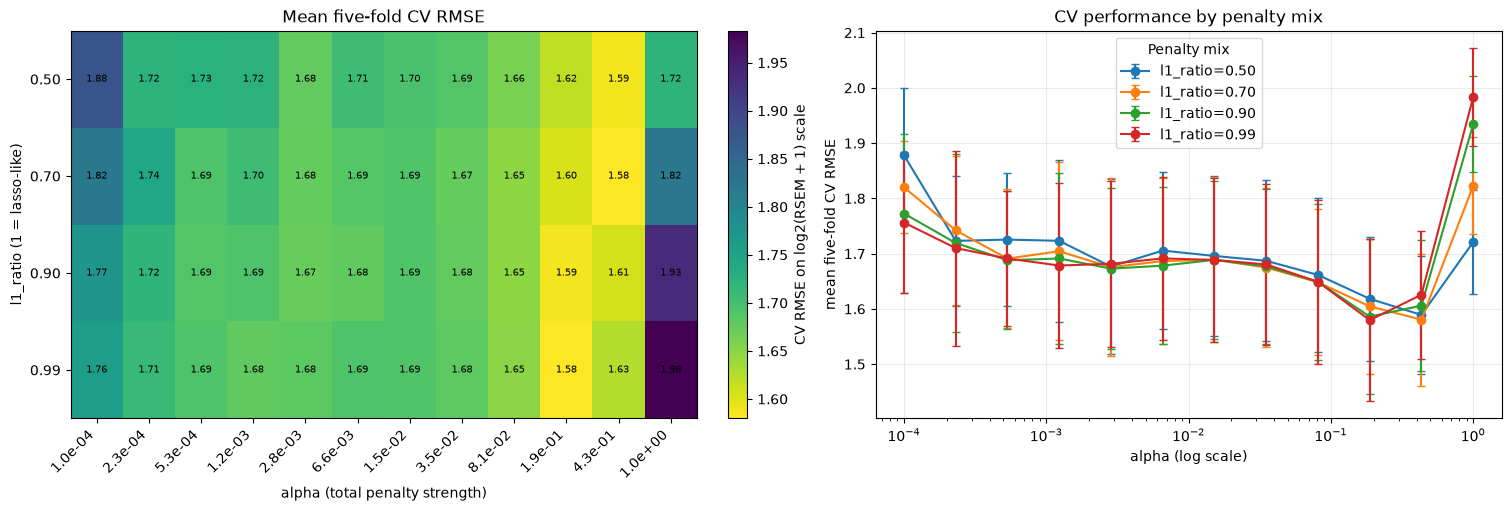

In [7]:
import matplotlib.pyplot as plt

cv_plot_data = cv_results.assign(
    alpha=cv_results['param_model__alpha'].astype(float),
    l1_ratio=cv_results['param_model__l1_ratio'].astype(float),
    cv_rmse=-cv_results['mean_test_score'],
    cv_rmse_sd=cv_results['std_test_score'],
).sort_values(['l1_ratio', 'alpha'])

rmse_grid = cv_plot_data.pivot(index='l1_ratio', columns='alpha', values='cv_rmse')
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)

# Each cell is the mean five-fold CV RMSE for one hyperparameter pair.
image = axes[0].imshow(rmse_grid.to_numpy(), aspect='auto', cmap='viridis_r')
axes[0].set_xticks(range(len(rmse_grid.columns)), [f'{alpha:.1e}' for alpha in rmse_grid.columns], rotation=45, ha='right')
axes[0].set_yticks(range(len(rmse_grid.index)), [f'{ratio:.2f}' for ratio in rmse_grid.index])
axes[0].set_xlabel('alpha (total penalty strength)')
axes[0].set_ylabel('l1_ratio (1 = lasso-like)')
axes[0].set_title('Mean five-fold CV RMSE')
for row, ratio in enumerate(rmse_grid.index):
    for column, alpha in enumerate(rmse_grid.columns):
        axes[0].text(column, row, f'{rmse_grid.loc[ratio, alpha]:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(image, ax=axes[0], label='CV RMSE on log2(RSEM + 1) scale')

# Lines reveal the alpha trend separately for each l1_ratio.
for ratio, group in cv_plot_data.groupby('l1_ratio', sort=True):
    axes[1].errorbar(
        group['alpha'], group['cv_rmse'], yerr=group['cv_rmse_sd'],
        marker='o', capsize=3, label=f'l1_ratio={ratio:.2f}',
    )
axes[1].set_xscale('log')
axes[1].set_xlabel('alpha (log scale)')
axes[1].set_ylabel('mean five-fold CV RMSE')
axes[1].set_title('CV performance by penalty mix')
axes[1].legend(title='Penalty mix')
axes[1].grid(alpha=0.25)
plt.show()